In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay



In [3]:
from google.colab import files
uploaded = files.upload()
data = pd.read_csv("food_calorie_dataset.csv")


Saving food_calorie_dataset.csv to food_calorie_dataset (1).csv


In [4]:
print(data.head())
print("\nDataset shape:", data.shape)

    Food_Name  Calories_per_100g_kcal
0        Idli                      58
1        Dosa                     168
2  Plain Rice                     130
3     Biryani                     180
4     Chapati                     120

Dataset shape: (21, 2)


In [5]:
print(data)

               Food_Name  Calories_per_100g_kcal
0                   Idli                      58
1                   Dosa                     168
2             Plain Rice                     130
3                Biryani                     180
4                Chapati                     120
5                  Poori                     330
6                   Vada                     290
7                 Pongal                     160
8                 Sambar                      75
9              Curd Rice                     150
10            Lemon Rice                     175
11           Tomato Rice                     170
12        Vegetable Rice                     160
13       Chicken Biryani                     200
14         Chicken Curry                     190
15            Fish Curry                     150
16  Paneer Butter Masala                     180
17                Potato                      77
18                Banana                      89
19                 A

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
X = data[["Calories_per_100g_kcal"]]
y = data["Food_Name"]
print("Input:")
print(X.head())
print("\nTarget:")
print(y.head())

Input:
   Calories_per_100g_kcal
0                      58
1                     168
2                     130
3                     180
4                     120

Target:
0          Idli
1          Dosa
2    Plain Rice
3       Biryani
4       Chapati
Name: Food_Name, dtype: object


In [7]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
model.fit(X, y)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [8]:
y_pred = model.predict(X)
print("Predicted Food Names:")
for actual, predicted in zip(y, y_pred):
    print("Actual:", actual, " | Predicted:", predicted)

Predicted Food Names:
Actual: Idli  | Predicted: Idli
Actual: Dosa  | Predicted: Dosa
Actual: Plain Rice  | Predicted: Plain Rice
Actual: Biryani  | Predicted: Paneer Butter Masala
Actual: Chapati  | Predicted: Chapati
Actual: Poori  | Predicted: Poori
Actual: Vada  | Predicted: Vada
Actual: Pongal  | Predicted: Pongal
Actual: Sambar  | Predicted: Sambar
Actual: Curd Rice  | Predicted: Fish Curry
Actual: Lemon Rice  | Predicted: Lemon Rice
Actual: Tomato Rice  | Predicted: Tomato Rice
Actual: Vegetable Rice  | Predicted: Pongal
Actual: Chicken Biryani  | Predicted: Chicken Biryani
Actual: Chicken Curry  | Predicted: Chicken Curry
Actual: Fish Curry  | Predicted: Fish Curry
Actual: Paneer Butter Masala  | Predicted: Paneer Butter Masala
Actual: Potato  | Predicted: Potato
Actual: Banana  | Predicted: Banana
Actual: Apple  | Predicted: Apple
Actual: chutney  | Predicted: chutney


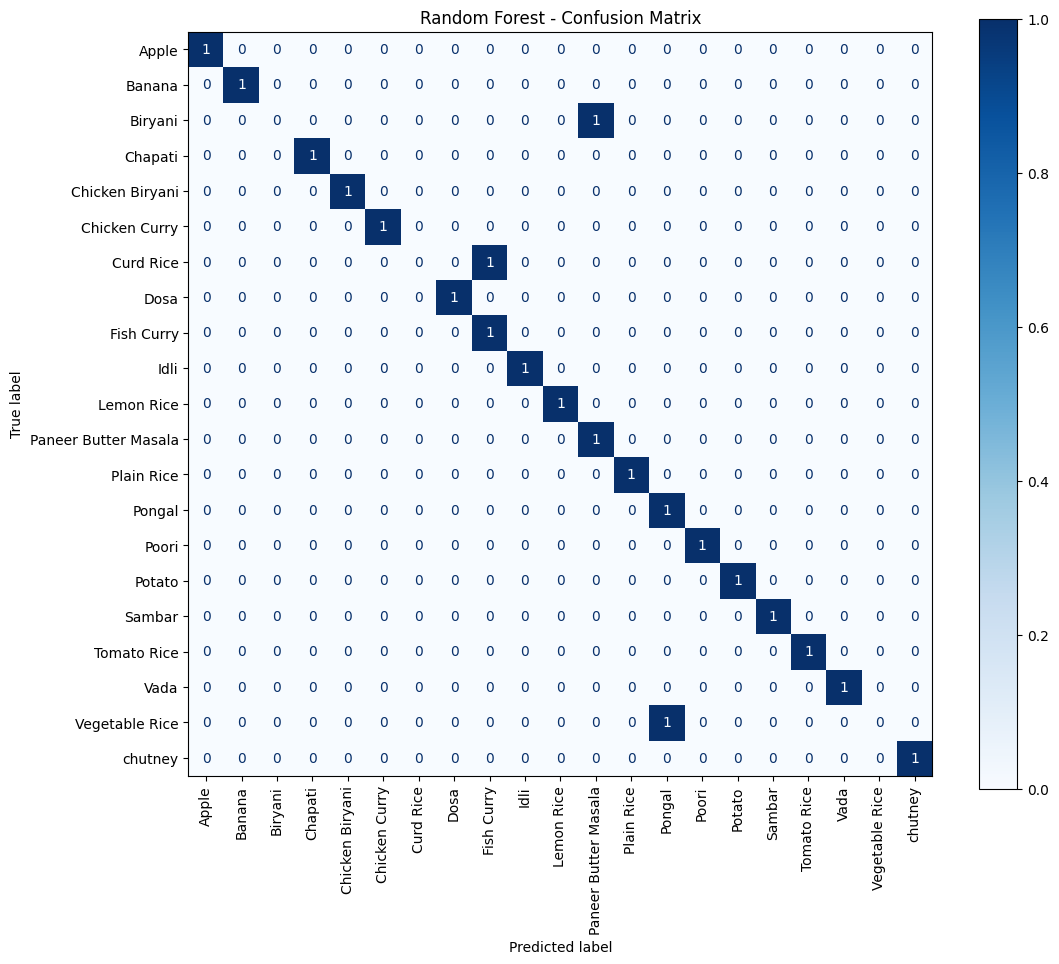

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)
fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues"
)
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [10]:
uploaded = files.upload()
image_name = list(uploaded.keys())[0]
print("Image uploaded:", image_name)

Saving dosa,sambar,chutney.png to dosa,sambar,chutney.png
Image uploaded: dosa,sambar,chutney.png


In [11]:
foods = ["Dosa", "Sambar", "Chutney"]
quantities = [150, 100, 50]
calories = []
for food, quantity in zip(foods, quantities):
    result = data[
        data["Food_Name"].str.lower() == food.lower()
    ]
    if not result.empty:
        calories_per_100g = result.iloc[0]["Calories_per_100g_kcal"]
        calorie = (calories_per_100g * quantity) / 100
        calories.append(calorie)
        print(
            food,
            "=",
            quantity,
            "g =",
            calorie,
            "kcal"
        )

Dosa = 150 g = 252.0 kcal
Sambar = 100 g = 75.0 kcal
Chutney = 50 g = 50.0 kcal


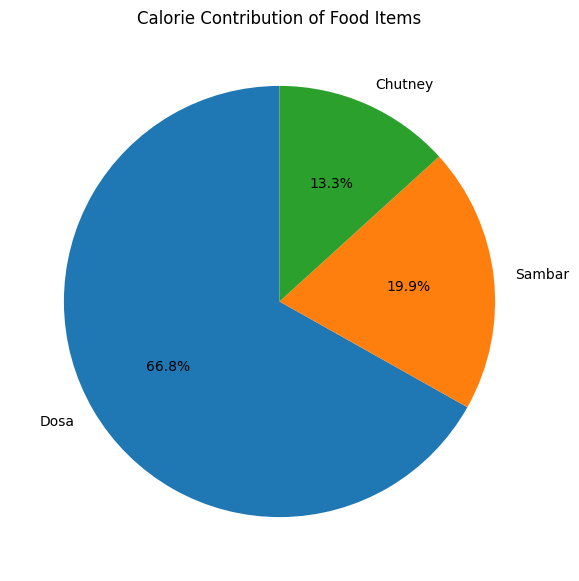

In [13]:
plt.figure(figsize=(7, 7))
plt.pie(
    calories,
    labels=foods,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Calorie Contribution of Food Items")
plt.show()

In [14]:
total_calories = sum(calories)
average_calories = total_calories / len(calories)
highest_index = calories.index(max(calories))
print("========== FOOD CALORIE REPORT ==========")
for food, calorie in zip(foods, calories):
    print(food, ":", calorie, "kcal")
print("-----------------------------------------")
print("Total Calories :", total_calories, "kcal")
print("Average Calories :", round(average_calories, 2), "kcal")
print("Highest Calorie Food :", foods[highest_index])
print("Highest Calories :", calories[highest_index], "kcal")

========== FOOD CALORIE REPORT ==========
Dosa : 252.0 kcal
Sambar : 75.0 kcal
Chutney : 50.0 kcal
-----------------------------------------
Total Calories : 377.0 kcal
Average Calories : 125.67 kcal
Highest Calorie Food : Dosa
Highest Calories : 252.0 kcal
